# Homework 6 — From features to an MLP, and a first look at `nn.Conv2d`

**Student:** Daniela Gonzalez
**Course:** Computer Vision and Speech Recognition — EADA
**Dataset:** MILK10k (5,240 lesions, one dermoscopic + one clinical image each)
**Task:** `diagnosis_1` — Benign / Indeterminate / Malignant, one prediction per lesion

**Code on GitHub**
- This notebook: https://github.com/Dgbaquero123/milk10k-eda/blob/main/notebooks/homework_part_6.ipynb
- MLP model, training loop and 32×32 pixel loader: https://github.com/Dgbaquero123/milk10k-eda/blob/main/milk10k_pipeline/mlp.py
- Session 5 baseline (features, metrics): https://github.com/Dgbaquero123/milk10k-eda/blob/main/milk10k_pipeline/baseline.py
- Project scoreboard (CSV): https://github.com/Dgbaquero123/milk10k-eda/blob/main/reports/scoreboard.csv

| question | section |
|---|---|
| 1. MLP's validation and test macro-F1 on the scoreboard, next to the Session 5 baseline | §1 |
| 2. `nn.Conv2d`: which arguments are Session 4's kernel size, stride and padding? | §2 |
| 3. MLP on raw pixels (32×32×3 = 3,072 numbers): better or worse than the baseline with features? Why? | §3, §4 |

**Protocol (same rules as Homework 5).**
- Unit = lesion; the committed Milestone 1 splits are used unchanged
  (train 3,668 / val 786 / test 786 lesions).
- Every learned statistic (feature scaler, pixel mean/std, class weights)
  is fitted on **train only**.
- **Early stopping uses an inner 15% split of train**, not the official
  val split. Val and test are therefore never seen during training or
  model selection, and both scores below are unbiased.
- Small networks on 3,668 lesions are noisy, so every MLP configuration
  is trained with **5 seeds** and reported as mean ± sd. The average of
  the 5 seeds' probabilities ("5-seed ensemble") is reported as well.
- Primary metric: macro-F1 (as in Sessions 3 and 5).

In [1]:
# --- Setup -------------------------------------------------------------------
import inspect
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import Image as IPyImage, display
from PIL import Image as PILImage

ROOT = Path.cwd().resolve()
if not (ROOT / "milk10k_pipeline").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from milk10k_pipeline import config
from milk10k_pipeline import baseline as bl
from milk10k_pipeline import mlp

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
torch.set_num_threads(2)

FIG = ROOT / "reports" / "figures_hw6"
RES = ROOT / "reports" / "hw6_results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe6",
    "grid.linewidth": 0.8, "font.size": 10, "axes.titlesize": 11,
})
CLASSES = bl.CLASSES
SEEDS = [0, 1, 2, 3, 4]
print("torch", torch.__version__, "| repository root:", ROOT.name)

torch 2.15.0+cu132 | repository root: milk10k-eda


In [2]:
# --- Data ---------------------------------------------------------------------
lesions = bl.load_lesion_table()
train = lesions[lesions.split == "train"].reset_index(drop=True)
val = lesions[lesions.split == "val"].reset_index(drop=True)
test = lesions[lesions.split == "test"].reset_index(drop=True)
y_tr = mlp.encode_labels(train.diagnosis_1)
y_val_lab, y_test_lab = val.diagnosis_1.values, test.diagnosis_1.values

counts = (lesions.groupby(["split", "diagnosis_1"]).size().unstack()
          .loc[["train", "val", "test"], CLASSES])
counts["total"] = counts.sum(axis=1)
display(counts)

diagnosis_1,Benign,Indeterminate,Malignant,total
split,,,,
train,1023,90,2555,3668
val,223,20,543,786
test,237,13,536,786


Helper used for every model: train one network per seed, evaluate each
on val and test, and also evaluate the average of their probabilities.

In [3]:
def run_seeds(X_tr, X_val, X_test, cfg_kwargs, seeds=SEEDS, keep_models=False):
    """Train one MLP per seed; return per-seed metrics, probabilities and runs."""
    rows, p_val, p_test, runs = [], [], [], []
    for s in seeds:
        r = mlp.train_mlp(X_tr, y_tr, mlp.TrainConfig(seed=s, **cfg_kwargs))
        pv, pt = mlp.predict_proba(r.model, X_val), mlp.predict_proba(r.model, X_test)
        mv = bl.metrics(y_val_lab, np.array(CLASSES)[pv.argmax(1)], pv)
        mt = bl.metrics(y_test_lab, np.array(CLASSES)[pt.argmax(1)], pt)
        rows.append({"seed": s, "best_epoch": r.best_epoch, "inner_val_f1": r.inner_val_f1,
                     "val_macro_f1": mv["macro_f1"], "test_macro_f1": mt["macro_f1"],
                     "test_balanced_acc": mt["balanced_acc"], "test_macro_auc": mt["macro_auc"],
                     "test_recall_Malignant": mt["recall_Malignant"], "seconds": r.seconds})
        p_val.append(pv)
        p_test.append(pt)
        runs.append(r if keep_models else None)
    return pd.DataFrame(rows), np.mean(p_val, 0), np.mean(p_test, 0), runs


def select_config(X_tr, grid, seeds=(0, 1, 2)):
    """Pick hidden sizes / dropout by mean INNER-val macro-F1 (val and test untouched)."""
    out = []
    for g in grid:
        f1s = [mlp.train_mlp(X_tr, y_tr, mlp.TrainConfig(seed=s, **g)).inner_val_f1 for s in seeds]
        out.append({**g, "inner_val_f1_mean": np.mean(f1s), "inner_val_f1_sd": np.std(f1s)})
    df = pd.DataFrame(out).sort_values("inner_val_f1_mean", ascending=False).reset_index(drop=True)
    return df, {k: df.loc[0, k] for k in grid[0]}


GRID = [{"hidden": h, "p_drop": p} for h in [(128,), (256, 128), (512, 256)] for p in [0.2, 0.5]]

## 1. MLP on the Session 5 features → scoreboard

**Input.** The Session 5 feature set chosen by cross-validation,
*hand-crafted + metadata*: colour, GLCM/LBP texture, the Session 4
filter bank and ABCD shape for both views, plus age, sex and site
(323 columns → 328 after one-hot encoding). They are preprocessed with
exactly the same `ColumnTransformer` as the baseline (median imputation,
standardisation, one-hot), fitted on train.

**Model.** `Linear → ReLU → Dropout` blocks and a final `Linear` to 3
logits, weighted cross-entropy (class weights from train, same formula
as Milestone 1), AdamW (lr 1e-3, weight decay 1e-4), batch 128, up to
300 epochs, early stopping on inner-val macro-F1 (patience 25), best
epoch restored. Hidden sizes and dropout are chosen from 6 options on
the inner split.

In [4]:
feat_cols = bl.feature_columns(lesions, ["color", "tex", "filt", "shape"], ("derm", "clin"), meta=True)
prep = bl._preprocessor(feat_cols).fit(train[feat_cols])
Xf_tr, Xf_val, Xf_test = (prep.transform(d[feat_cols]).astype(np.float32) for d in (train, val, test))
print("feature matrix:", Xf_tr.shape, "| raw columns:", len(feat_cols))

t0 = time.time()
grid_f, cfg_f = select_config(Xf_tr, GRID)
grid_f.to_csv(RES / "config_selection_features.csv", index=False)
print(f"config selection on the inner split ({time.time() - t0:.0f}s)")
display(grid_f)
print("chosen:", cfg_f)

feature matrix: (3668, 328) | raw columns: 323


config selection on the inner split (141s)


,hidden,p_drop,inner_val_f1_mean,inner_val_f1_sd
0,"(256, 128)",0.2,0.596,0.028
1,"(128,)",0.5,0.594,0.029
2,"(512, 256)",0.5,0.587,0.033
3,"(256, 128)",0.5,0.586,0.025
4,"(128,)",0.2,0.578,0.023
5,"(512, 256)",0.2,0.574,0.023


chosen: {'hidden': (256, 128), 'p_drop': np.float64(0.2)}


In [5]:
seeds_f, pval_f, ptest_f, runs_f = run_seeds(Xf_tr, Xf_val, Xf_test, cfg_f, keep_models=True)
seeds_f.to_csv(RES / "mlp_features_seeds.csv", index=False)
print("MLP on features — one row per seed")
display(seeds_f)
print("mean ± sd: val macro-F1 {:.3f} ± {:.3f} | test macro-F1 {:.3f} ± {:.3f}".format(
    seeds_f.val_macro_f1.mean(), seeds_f.val_macro_f1.std(),
    seeds_f.test_macro_f1.mean(), seeds_f.test_macro_f1.std()))
print("parameters:", mlp.n_params(runs_f[0].model))

MLP on features — one row per seed


,seed,best_epoch,inner_val_f1,val_macro_f1,test_macro_f1,test_balanced_acc,test_macro_auc,test_recall_Malignant,seconds
0,0,33,0.636,0.510,0.597,0.608,0.833,0.871,5.941
1,1,50,0.571,0.585,0.591,0.652,0.845,0.825,7.720
2,2,74,0.582,0.575,0.604,0.641,0.836,0.892,10.294
3,3,36,0.621,0.566,0.618,0.636,0.833,0.869,6.377
4,4,10,0.672,0.547,0.616,0.683,0.843,0.849,3.782


mean ± sd: val macro-F1 0.556 ± 0.030 | test macro-F1 0.605 ± 0.012
parameters: 117507


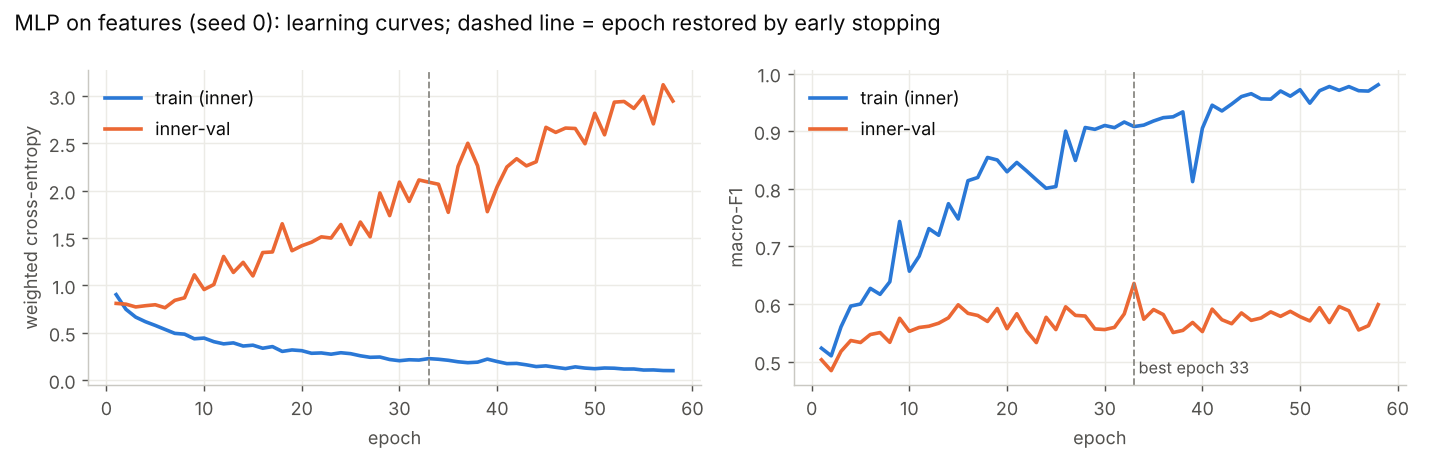

In [6]:
def plot_curves(hist, best_epoch, title, path):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(hist.epoch, hist.train_loss, color=BLUE, lw=2, label="train (inner)")
    ax[0].plot(hist.epoch, hist.inner_val_loss, color=ORANGE, lw=2, label="inner-val")
    ax[0].set_ylabel("weighted cross-entropy")
    ax[1].plot(hist.epoch, hist.train_macro_f1, color=BLUE, lw=2, label="train (inner)")
    ax[1].plot(hist.epoch, hist.inner_val_macro_f1, color=ORANGE, lw=2, label="inner-val")
    ax[1].set_ylabel("macro-F1")
    for a in ax:
        a.axvline(best_epoch, color=GREY, ls="--", lw=1)
        a.set_xlabel("epoch")
        a.legend(frameon=False)
    ax[1].text(best_epoch, ax[1].get_ylim()[0] + 0.02, f" best epoch {best_epoch}", color=INK2, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=130)
    plt.close()
    display(IPyImage(filename=str(path), width=900))


plot_curves(runs_f[0].history, runs_f[0].best_epoch,
            "MLP on features (seed 0): learning curves; dashed line = epoch restored by early stopping",
            FIG / "fig1_mlp_features_curves.png")

### The Session 5 baseline on the same footing

The Session 5 baseline is a soft-voting ensemble of tuned
HistGradientBoosting and SVM-RBF on the same 323 columns. Its official
test score (0.697) came from a model **refitted on train + val**, while
the MLPs here are fitted on **train only**. To compare like with like,
the baseline is rebuilt from the saved hyperparameters
(`reports/hw5_results/tuning.csv`), fitted on train only, and scored on
val and test. The val score must reproduce the Session 5 number.

In [7]:
import ast
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

tuning = pd.read_csv(ROOT / "reports" / "hw5_results" / "tuning.csv")
members = []
for _, r in tuning.iterrows():
    params = {f"model__{k}": v for k, v in ast.literal_eval(r["best_params"]).items()}
    members.append((r["model"], bl.make_pipeline(bl.make_models()[r["model"]], feat_cols).set_params(**params)))
baseline = VotingClassifier(members, voting="soft").fit(train[feat_cols], train["diagnosis_1"])

pval_b = baseline.predict_proba(val[feat_cols])
ptest_b = baseline.predict_proba(test[feat_cols])
hw5_val = pd.read_csv(ROOT / "reports" / "hw5_results" / "val_candidates.csv").set_index("candidate")
mv_b = bl.metrics(y_val_lab, np.array(CLASSES)[pval_b.argmax(1)], pval_b)
mt_b = bl.metrics(y_test_lab, np.array(CLASSES)[ptest_b.argmax(1)], ptest_b)
print(f"baseline (fit on train): val macro-F1 {mv_b['macro_f1']:.3f} "
      f"(Session 5 notebook: {hw5_val.loc['Ensemble(HistGB+SVM-RBF)', 'macro_f1']:.3f}) | "
      f"test macro-F1 {mt_b['macro_f1']:.3f}")
assert abs(mv_b["macro_f1"] - hw5_val.loc["Ensemble(HistGB+SVM-RBF)", "macro_f1"]) < 1e-6

baseline (fit on train): val macro-F1 0.563 (Session 5 notebook: 0.563) | test macro-F1 0.664


In [8]:
# --- Scoreboard (part 1) ---------------------------------------------------
from sklearn.dummy import DummyClassifier

hw5_official = pd.read_csv(ROOT / "reports" / "hw5_results" / "test_metrics_argmax_ci.csv", index_col=0)["value"]
scoreboard = []


def add_row(model, inputs, n_inputs, fit_on, val_f1, test_m, val_sd=np.nan, test_sd=np.nan, n_params=np.nan):
    scoreboard.append({"session": SESSION, "model": model, "input": inputs, "n_inputs": n_inputs,
                       "n_params": n_params, "fit_on": fit_on,
                       "val_macro_f1": val_f1, "val_sd": val_sd,
                       "test_macro_f1": test_m["macro_f1"], "test_sd": test_sd,
                       "test_balanced_acc": test_m["balanced_acc"],
                       "test_macro_auc": test_m.get("macro_auc", np.nan),
                       "test_recall_Malignant": test_m["recall_Malignant"]})


SESSION = 3
for name in ["always-Malignant", "stratified-random"]:
    d = (DummyClassifier(strategy="constant", constant="Malignant") if name == "always-Malignant"
         else DummyClassifier(strategy="stratified", random_state=0)).fit(np.zeros((len(train), 1)), train.diagnosis_1)
    mv = bl.metrics(y_val_lab, d.predict(np.zeros((len(val), 1))))
    mt = bl.metrics(y_test_lab, d.predict(np.zeros((len(test), 1))))
    mt["macro_auc"] = 0.5
    add_row(f"dummy: {name}", "—", 0, "train", mv["macro_f1"], mt)

SESSION = 5
add_row("Baseline: HistGB + SVM-RBF ensemble", "hand-crafted features + meta", len(feat_cols),
        "train", mv_b["macro_f1"], mt_b)
add_row("Baseline: HistGB + SVM-RBF ensemble (official)", "hand-crafted features + meta", len(feat_cols),
        "train + val", np.nan,
        {"macro_f1": hw5_official["macro_f1"], "balanced_acc": hw5_official["balanced_acc"],
         "macro_auc": hw5_official["macro_auc"], "recall_Malignant": hw5_official["recall_Malignant"]})

SESSION = 6
mt_fe = bl.metrics(y_test_lab, np.array(CLASSES)[ptest_f.argmax(1)], ptest_f)
add_row(f"MLP {cfg_f['hidden']}, dropout {cfg_f['p_drop']} (mean of 5 seeds)", "hand-crafted features + meta",
        len(feat_cols), "train", seeds_f.val_macro_f1.mean(),
        {"macro_f1": seeds_f.test_macro_f1.mean(), "balanced_acc": seeds_f.test_balanced_acc.mean(),
         "macro_auc": seeds_f.test_macro_auc.mean(), "recall_Malignant": seeds_f.test_recall_Malignant.mean()},
        val_sd=seeds_f.val_macro_f1.std(), test_sd=seeds_f.test_macro_f1.std(),
        n_params=mlp.n_params(runs_f[0].model))
add_row("MLP (5-seed ensemble)", "hand-crafted features + meta", len(feat_cols), "train",
        bl.metrics(y_val_lab, np.array(CLASSES)[pval_f.argmax(1)], pval_f)["macro_f1"], mt_fe,
        n_params=5 * mlp.n_params(runs_f[0].model))

def pretty(sb):
    """Compact view of the scoreboard for the report (the CSV keeps every column)."""
    def ms(m, sd):
        return ["—" if np.isnan(a) else (f"{a:.3f}" if np.isnan(b) else f"{a:.3f} ± {b:.3f}")
                for a, b in zip(m, sd)]
    return pd.DataFrame({
        "session": sb.session.values, "model": sb.model.values, "input": sb.input.values,
        "fit on": sb.fit_on.values,
        "val macro-F1": ms(sb.val_macro_f1, sb.val_sd), "test macro-F1": ms(sb.test_macro_f1, sb.test_sd),
        "test AUC": [f"{v:.3f}" for v in sb.test_macro_auc],
        "test recall Malignant": [f"{v:.3f}" for v in sb.test_recall_Malignant]})


print("SCOREBOARD — after Question 1")
display(pretty(pd.DataFrame(scoreboard)))

SCOREBOARD — after Question 1


,session,model,input,fit on,val macro-F1,test macro-F1,test AUC,test recall Malignant
0,3,dummy: always-Malignant,—,train,0.272,0.270,0.500,1.000
1,3,dummy: stratified-random,—,train,0.325,0.326,0.500,0.703
2,5,Baseline: HistGB + SVM-RBF ensemble,hand-crafted features + meta,train,0.563,0.664,0.873,0.916
3,5,Baseline: HistGB + SVM-RBF ensemble (official),hand-crafted features + meta,train + val,—,0.697,0.879,0.907
4,6,"MLP (256, 128), dropout 0.2 (mean of 5 seeds)",hand-crafted features + meta,train,0.556 ± 0.030,0.605 ± 0.012,0.838,0.861
5,6,MLP (5-seed ensemble),hand-crafted features + meta,train,0.576,0.632,0.858,0.896


**Is the MLP–baseline difference real?** Paired bootstrap on the 786
test lesions: resample lesions with replacement 2,000 times and
recompute *MLP − baseline* macro-F1 on the same resample (both fitted
on train only).

In [9]:
from sklearn.metrics import roc_auc_score


def _auc(y, p):
    return roc_auc_score(y, p, labels=CLASSES, multi_class="ovr", average="macro")


def paired_bootstrap(p_a, p_b, y, n_boot=2000, seed=0):
    """Paired bootstrap of A − B on the same resampled test lesions (macro-F1 and macro AUC)."""
    rng = np.random.default_rng(seed)
    pa, pb = np.array(CLASSES)[p_a.argmax(1)], np.array(CLASSES)[p_b.argmax(1)]
    d_f1, d_auc = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) < len(CLASSES):
            continue
        d_f1.append(bl.metrics(y[i], pa[i])["macro_f1"] - bl.metrics(y[i], pb[i])["macro_f1"])
        d_auc.append(_auc(y[i], p_a[i]) - _auc(y[i], p_b[i]))
    d_f1, d_auc = np.array(d_f1), np.array(d_auc)
    return {"diff": bl.metrics(y, pa)["macro_f1"] - bl.metrics(y, pb)["macro_f1"],
            "ci_low": np.quantile(d_f1, 0.025), "ci_high": np.quantile(d_f1, 0.975),
            "P(diff>0)": (d_f1 > 0).mean(),
            "auc_diff": _auc(y, p_a) - _auc(y, p_b),
            "auc_ci_low": np.quantile(d_auc, 0.025), "auc_ci_high": np.quantile(d_auc, 0.975)}


pb_f = paired_bootstrap(ptest_f, ptest_b, y_test_lab)
print("test macro-F1, MLP 5-seed ensemble − baseline (both fit on train): "
      f"{pb_f['diff']:+.3f}  95% CI [{pb_f['ci_low']:+.3f}, {pb_f['ci_high']:+.3f}]  "
      f"P(MLP better) = {pb_f['P(diff>0)']:.2f}")
print("test macro AUC,  MLP 5-seed ensemble − baseline: "
      f"{pb_f['auc_diff']:+.3f}  95% CI [{pb_f['auc_ci_low']:+.3f}, {pb_f['auc_ci_high']:+.3f}]")
print("\nConfusion matrix on test — MLP 5-seed ensemble")
display(bl.confusion(y_test_lab, np.array(CLASSES)[ptest_f.argmax(1)]))
print("Confusion matrix on test — baseline (fit on train)")
display(bl.confusion(y_test_lab, np.array(CLASSES)[ptest_b.argmax(1)]))

test macro-F1, MLP 5-seed ensemble − baseline (both fit on train): -0.032  95% CI [-0.089, +0.043]  P(MLP better) = 0.17
test macro AUC,  MLP 5-seed ensemble − baseline: -0.014  95% CI [-0.037, +0.006]

Confusion matrix on test — MLP 5-seed ensemble


,pred Benign,pred Indeterminate,pred Malignant
true Benign,152,5,80
true Indeterminate,2,5,6
true Malignant,49,7,480


Confusion matrix on test — baseline (fit on train)


,pred Benign,pred Indeterminate,pred Malignant
true Benign,150,1,86
true Indeterminate,2,4,7
true Malignant,44,1,491


### Question 1 — Answer

| model (all fitted on **train** only) | val macro-F1 | test macro-F1 | test macro AUC |
|---|---|---|---|
| dummy: stratified-random (Session 3) | 0.325 | 0.326 | 0.500 |
| **Session 5 baseline**: HistGB + SVM-RBF ensemble, 323 features | **0.563** | **0.664** | 0.873 |
| **MLP** (256, 128), dropout 0.2, same 323 features — mean ± sd of 5 seeds | **0.556 ± 0.030** | **0.605 ± 0.012** | 0.838 |
| **MLP**, 5-seed ensemble (average of the probabilities) | **0.576** | **0.632** | 0.858 |

(The official Session 5 number, 0.697 on test, comes from refitting the
baseline on train + val; it is kept in the scoreboard as a separate row.)

- **On validation the MLP matches the baseline** (0.556 per seed, 0.576
  for the ensemble, vs 0.563). **On test it is a little lower** (0.605
  per seed, 0.632 ensemble, vs 0.664), and also lower in macro AUC
  (0.858 vs 0.873).
- **The gap is not significant.** Paired bootstrap on the test lesions:
  MLP ensemble − baseline = −0.032 macro-F1, 95% CI [−0.089, +0.043];
  the bootstrap puts the MLP ahead in only 17% of resamples. In macro
  AUC the difference is −0.014, 95% CI [−0.037, +0.006]. The seed
  spread is about as large as the gap: one seed scores 0.510 on val and
  another 0.585.
- **Where the errors differ.** The MLP predicts Indeterminate more
  often (17 test lesions, 5 correct, vs 6 and 4 for the baseline). It
  also misses more malignant lesions: 56 vs 45 (Malignant recall 0.896
  vs 0.916).
- **Why no gain.** The input is the same 323 hand-crafted numbers. The
  features already carry the useful information in a form that trees
  and an RBF kernel exploit well. An MLP is just another flexible
  function of those numbers. On ~3,100 training lesions it is noisier
  (5 seeds are needed for a stable estimate), and early stopping
  happens after 10–74 epochs. **On tabular features, gradient boosting
  and SVM remain at least as good as an MLP.** The MLP's real advantage
  (learning the features itself) only appears when it gets images,
  which is §3.

## 2. `nn.Conv2d`: where are Session 4's kernel size, stride and padding?

The signature and the relevant part of the official docstring:

In [10]:
print("nn.Conv2d" + str(inspect.signature(nn.Conv2d)))
doc = nn.Conv2d.__doc__
print(doc[doc.find("Args:"): doc.find("Args:") + 1060])
print(doc[doc.find("Shape:"): doc.find("Shape:") + 760])
first = [l.strip() for l in doc.splitlines() if "cross-correlation" in l]
print("Note from the docstring:", first[0] if first else "")

nn.Conv2d(in_channels: int, out_channels: int, kernel_size: Union[int, tuple[int, int]], stride: Union[int, tuple[int, int]] = 1, padding: Union[str, int, tuple[int, int]] = 0, dilation: Union[int, tuple[int, int]] = 1, groups: int = 1, bias: bool = True, padding_mode: Literal['zeros', 'reflect', 'replicate', 'circular'] = 'zeros', device=None, dtype=None) -> None
Args:
        in_channels (int): Number of channels in the input image
        out_channels (int): Number of channels produced by the convolution
        kernel_size (int or tuple): Size of the convolving kernel
        stride (int or tuple, optional): Stride of the convolution. Default: 1
        padding (int, tuple or str, optional): Padding added to all four sides of
            the input. Default: 0
        dilation (int or tuple, optional): Spacing between kernel elements. Default: 1
        groups (int, optional): Number of blocked connections from input
            channels to output channels. Default: 1
        bias (

| Session 4 concept | `nn.Conv2d` argument | notes |
|---|---|---|
| **kernel size** — the size of the filter mask (3×3 Sobel, 5×5 Gaussian, 21×21 Gabor) | **`kernel_size`** | int or (h, w). The kernel values themselves are `conv.weight`, shape `(out_channels, in_channels/groups, kh, kw)`; in a CNN they are *learned* instead of hand-designed. |
| **stride** — how many pixels the window moves between two outputs | **`stride`** | default 1 (every pixel, as in Session 4). `stride=2` halves the output size. |
| **padding** — how the border is handled so the output keeps the input size | **`padding`** + **`padding_mode`** | `padding` = how many pixels are added on each side (int, tuple, or `"same"`/`"valid"`); `padding_mode` = what is added: `'zeros'` (default), `'reflect'`, `'replicate'`, `'circular'` — the same idea as `mode=` in `scipy.ndimage`. |
| (related) number of filters in the filter bank | `out_channels` | one output channel per filter, e.g. 2 for Sobel x and y. |
| (related) grey vs RGB input | `in_channels` | 1 for a grey image, 3 for RGB. |
| (related) spacing between kernel taps | `dilation` | 1 = ordinary convolution. |

Two details matter when reproducing Session 4 results with `nn.Conv2d`:
it computes a **cross-correlation** (the kernel is *not* flipped), and
its `'reflect'` mode is SciPy's `'mirror'` mode (SciPy's default
`'reflect'` repeats the edge pixel). The cell below checks both by
loading the Sobel-x kernel into a `Conv2d` and comparing with SciPy on a
MILK10k image, then verifies the output-size formula of the docstring.

In [11]:
from scipy import ndimage

sample = train.query("dx == 'MEL'").iloc[0]
gray = np.asarray(PILImage.open(config.image_path(sample.derm_id)).convert("L").resize((224, 224)),
                  dtype=np.float32) / 255.0
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)

conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1,
                 padding_mode="reflect", bias=False)
with torch.no_grad():
    conv.weight[:] = torch.from_numpy(sobel_x)[None, None]
    out_torch = conv(torch.from_numpy(gray)[None, None])[0, 0].numpy()

out_corr = ndimage.correlate(gray, sobel_x, mode="mirror")
out_conv = ndimage.convolve(gray, sobel_x, mode="mirror")
out_refl = ndimage.correlate(gray, sobel_x, mode="reflect")
inner = (slice(1, -1), slice(1, -1))
checks = pd.DataFrame({
    "comparison with nn.Conv2d(k=3, s=1, p=1, reflect)": [
        "scipy correlate, mode='mirror'", "scipy convolve (kernel flipped), mode='mirror'",
        "scipy correlate, mode='reflect' (edge repeated)"],
    "max |difference| (whole image)": [np.abs(out_torch - out_corr).max(), np.abs(out_torch - out_conv).max(),
                                       np.abs(out_torch - out_refl).max()],
    "max |difference| (interior only)": [np.abs(out_torch - out_corr)[inner].max(),
                                         np.abs(out_torch - out_conv)[inner].max(),
                                         np.abs(out_torch - out_refl)[inner].max()],
})
display(checks)

,"comparison with nn.Conv2d(k=3, s=1, p=1, reflect)",max |difference| (whole image),max |difference| (interior only)
0,"scipy correlate, mode='mirror'",1.192e-07,1.192e-07
1,"scipy convolve (kernel flipped), mode='mirror'",2.627e+00,2.627e+00
2,"scipy correlate, mode='reflect' (edge repeated)",5.412e-01,1.192e-07


In [12]:
def out_size(h, k, s, p, d=1):
    return (h + 2 * p - d * (k - 1) - 1) // s + 1


size_rows = []
for k, s, p in [(3, 1, 1), (3, 1, 0), (3, 2, 1), (5, 1, 2), (7, 2, 3), (21, 1, 10)]:
    c = nn.Conv2d(3, 8, kernel_size=k, stride=s, padding=p)
    h_real = c(torch.zeros(1, 3, 224, 224)).shape[-1]
    size_rows.append({"kernel_size": k, "stride": s, "padding": p, "H_in": 224,
                      "H_out (formula)": out_size(224, k, s, p), "H_out (nn.Conv2d)": h_real,
                      "weights + bias": sum(q.numel() for q in c.parameters())})
size_df = pd.DataFrame(size_rows)
assert (size_df["H_out (formula)"] == size_df["H_out (nn.Conv2d)"]).all()
display(size_df)

,kernel_size,stride,padding,H_in,H_out (formula),H_out (nn.Conv2d),weights + bias
0,3,1,1,224,224,224,224
1,3,1,0,224,222,222,224
2,3,2,1,224,112,112,224
3,5,1,2,224,224,224,608
4,7,2,3,224,112,112,1184
5,21,1,10,224,224,224,10592


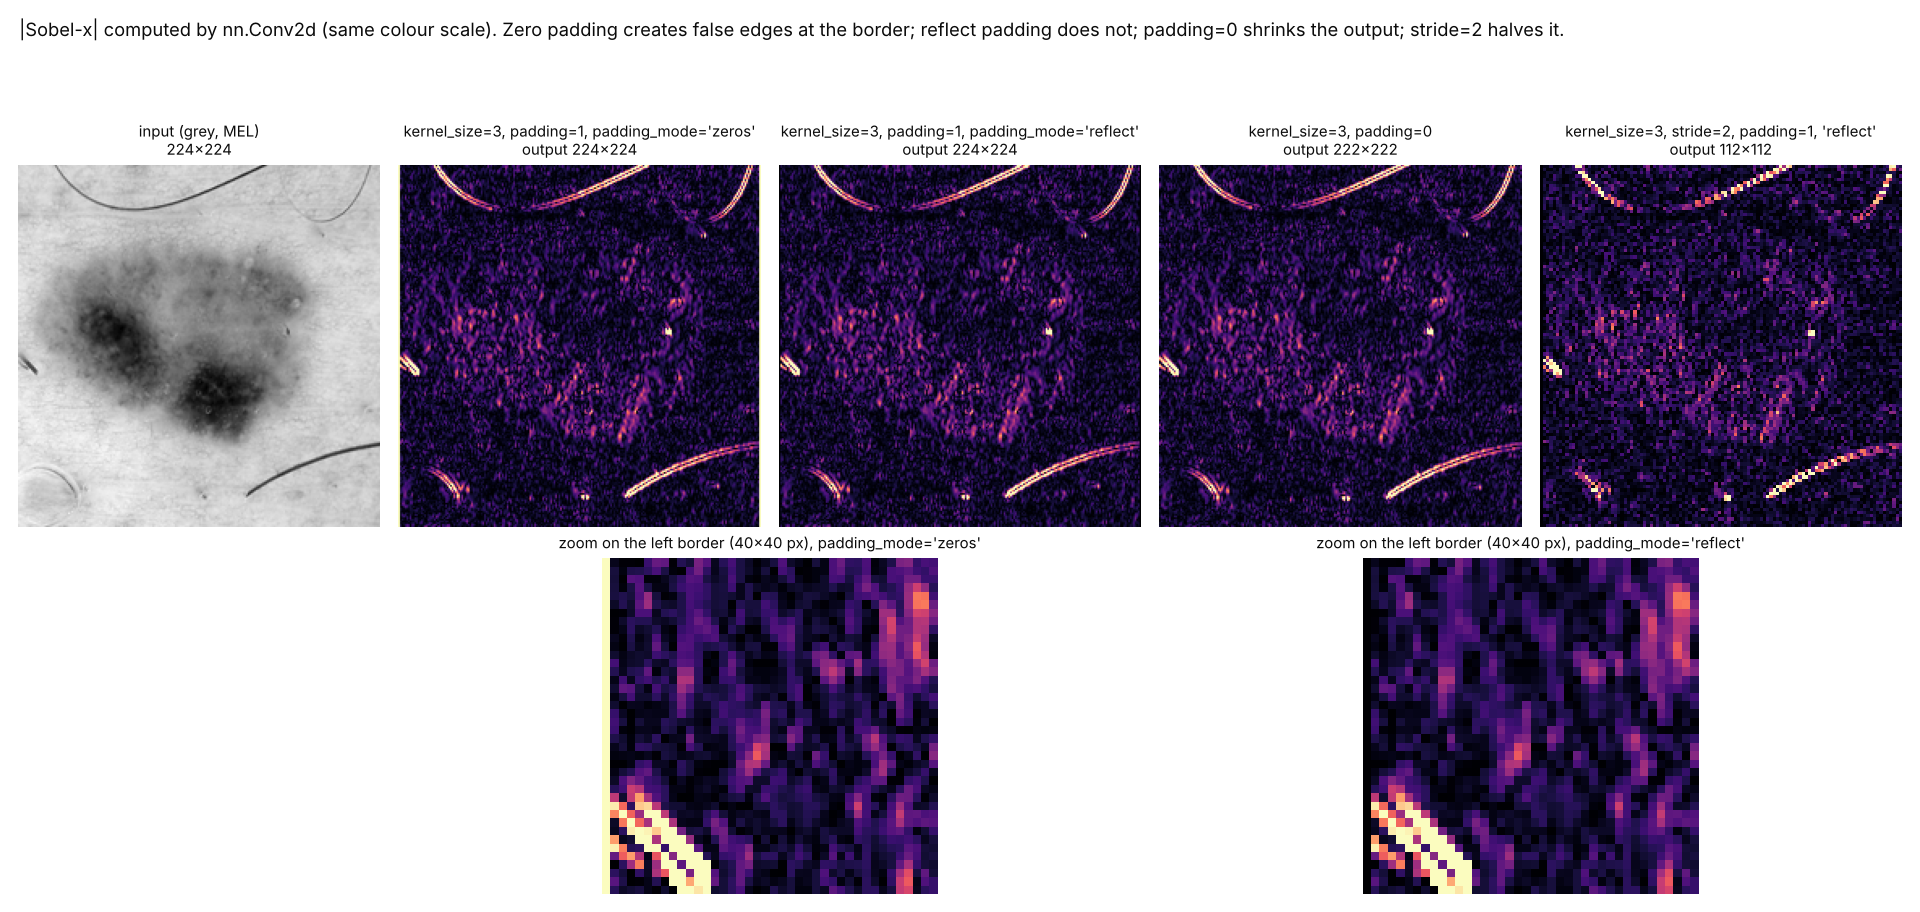

In [13]:
fig = plt.figure(figsize=(16, 7.6))
gs = fig.add_gridspec(2, 5, height_ratios=[1, 0.75])
ax = [fig.add_subplot(gs[0, j]) for j in range(5)]
ax[0].imshow(gray, cmap="gray")
ax[0].set_title(f"input (grey, MEL)\n{gray.shape[0]}×{gray.shape[1]}", fontsize=9)
variants = [("padding=1, padding_mode='zeros'", dict(stride=1, padding=1)),
            ("padding=1, padding_mode='reflect'", dict(stride=1, padding=1, padding_mode="reflect")),
            ("padding=0", dict(stride=1, padding=0)),
            ("stride=2, padding=1, 'reflect'", dict(stride=2, padding=1, padding_mode="reflect"))]
vmax = np.percentile(np.abs(out_torch), 99.5)
outs = []
for a, (title, kw) in zip(ax[1:], variants):
    c = nn.Conv2d(1, 1, 3, bias=False, **kw)
    with torch.no_grad():
        c.weight[:] = torch.from_numpy(sobel_x)[None, None]
        o = c(torch.from_numpy(gray)[None, None])[0, 0].numpy()
    outs.append(o)
    a.imshow(np.abs(o), cmap="magma", vmin=0, vmax=vmax)
    a.set_title(f"kernel_size=3, {title}\noutput {o.shape[0]}×{o.shape[1]}", fontsize=9)
crop = (slice(90, 130), slice(0, 40))                       # left border, rows 90-129
for j, (o, name) in enumerate([(outs[0], "'zeros'"), (outs[1], "'reflect'")]):
    a = fig.add_subplot(gs[1, 1 + 2 * j: 3 + 2 * j])
    a.imshow(np.abs(o[crop]), cmap="magma", vmin=0, vmax=vmax, interpolation="nearest")
    a.set_title(f"zoom on the left border (40×40 px), padding_mode={name}", fontsize=9)
    a.axis("off")
for a in ax:
    a.axis("off")
fig.suptitle("|Sobel-x| computed by nn.Conv2d (same colour scale). Zero padding creates false edges at the "
             "border; reflect padding does not; padding=0 shrinks the output; stride=2 halves it.",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(FIG / "fig2_conv2d_sobel.png", dpi=120)
plt.close()
display(IPyImage(filename=str(FIG / "fig2_conv2d_sobel.png"), width=950))

### Question 2 — Answer

- **Kernel size → `kernel_size`.** The weights of that kernel are
  `conv.weight` with shape `(out_channels, in_channels, kh, kw)`. Loading
  the Session 4 Sobel kernel into it reproduces SciPy exactly (max
  difference ≈ 1e-7, float rounding).
- **Stride → `stride`** (default 1). With `stride=2` a 224×224 image
  gives a 112×112 output.
- **Padding → `padding`** (how many pixels per side, or `"same"`) **and
  `padding_mode`** (what values: zeros, reflect, replicate, circular).
  With kernel 3 and `padding=1` the output stays 224×224; with
  `padding=0` it shrinks to 222×222, exactly as the docstring formula
  H_out = ⌊(H_in + 2·padding − dilation·(kernel_size − 1) − 1)/stride + 1⌋
  predicts for all six settings tested.
- With the default `padding_mode='zeros'` the image is surrounded by
  black pixels, which Sobel reports as strong false edges along the
  border (figure). `'reflect'` removes them. This is the same border
  question as Session 4.
- `nn.Conv2d` computes a **cross-correlation**: using SciPy's `convolve`
  (which flips the kernel) gives the opposite sign for Sobel. Its
  `'reflect'` padding equals SciPy's `'mirror'`; SciPy's `'reflect'`
  only matches in the image interior.
- The real difference with Session 4: there we chose the kernels
  (Sobel, Gaussian, Gabor); in a CNN `out_channels` kernels are learned.
  A layer `nn.Conv2d(3, 8, kernel_size=3)` has only 224 parameters
  because the same small kernel is reused at every position (weight
  sharing). This is exactly what the raw-pixel MLP in §3 lacks.

## 3. MLP on raw pixels (32×32×3 = 3,072 numbers)

**Input.** The dermoscopic image of each lesion, resized to 32×32 with
an anti-aliased (box) filter and flattened to 3,072 numbers, each
channel standardised with the train mean and std. Everything else is
identical to §1: same MLP family, same 6-option selection on the inner
split, same 5 seeds, same early stopping.

Two extra runs answer *why*:
- **both views** (dermoscopic + clinical, 6,144 numbers), the closest
  pixel equivalent of the feature input;
- **shuffled pixels**: the 3,072 inputs are permuted with one fixed
  random permutation (the same for every lesion). If the MLP used the
  spatial layout of the image, this would destroy its performance.

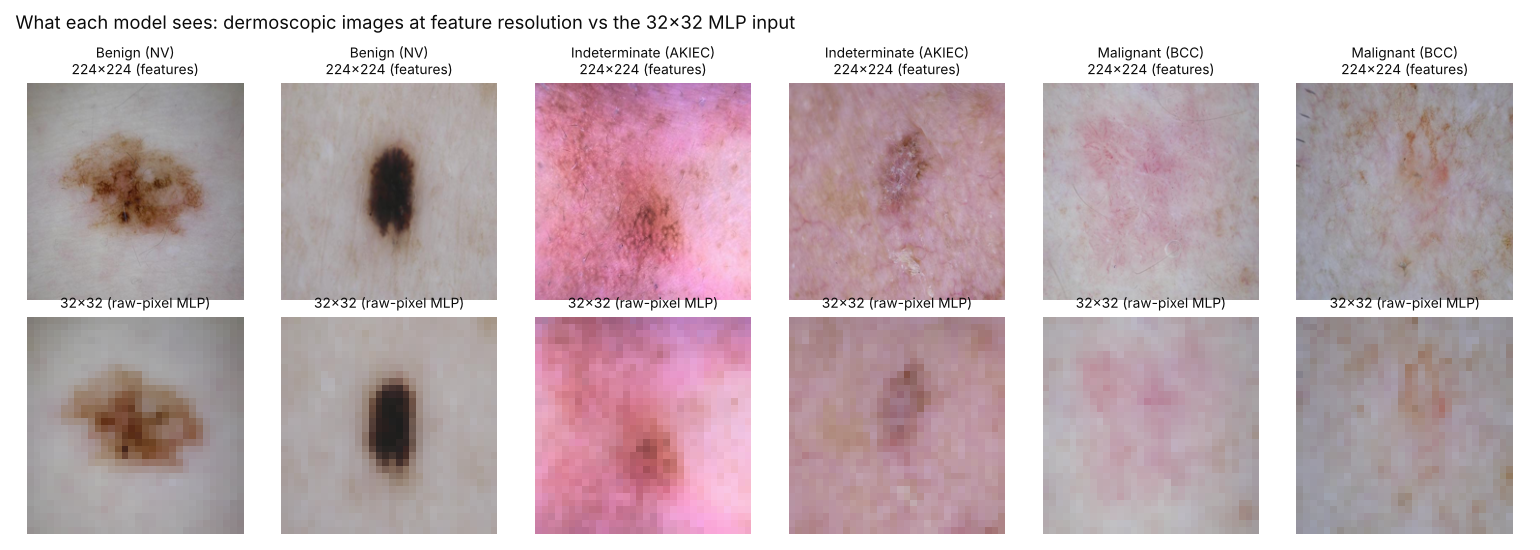

In [14]:
pixels = mlp.load_pixels(32)

fig, ax = plt.subplots(2, 6, figsize=(14, 5))
demo = pd.concat([train[train.diagnosis_1 == c].sample(2, random_state=3) for c in CLASSES])
for j, (_, r) in enumerate(demo.iterrows()):
    ax[0, j].imshow(PILImage.open(config.image_path(r.derm_id)).convert("RGB").resize((224, 224)))
    ax[0, j].set_title(f"{r.diagnosis_1} ({r.dx})\n224×224 (features)", fontsize=9)
    ax[1, j].imshow(pixels[r.derm_id], interpolation="nearest")
    ax[1, j].set_title("32×32 (raw-pixel MLP)", fontsize=9)
for a in ax.ravel():
    a.axis("off")
fig.suptitle("What each model sees: dermoscopic images at feature resolution vs the 32×32 MLP input",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig3_pixels_32.png", dpi=110)
plt.close()
display(IPyImage(filename=str(FIG / "fig3_pixels_32.png"), width=950))

In [15]:
def pixel_inputs(views):
    Xs = [mlp.pixel_matrix(d, pixels, views) for d in (train, val, test)]
    st = mlp.ChannelStandardizer(3 * len(views)).fit(Xs[0])
    return [st.transform(X) for X in Xs], st


(Xp_tr, Xp_val, Xp_test), st_derm = pixel_inputs(("derm",))
print("raw pixels, dermoscopic:", Xp_tr.shape, "| train channel mean (RGB):", st_derm.mean_.round(3),
      "std:", st_derm.std_.round(3))

t0 = time.time()
grid_p, cfg_p = select_config(Xp_tr, GRID)
grid_p.to_csv(RES / "config_selection_pixels.csv", index=False)
print(f"config selection on the inner split ({time.time() - t0:.0f}s)")
display(grid_p)
print("chosen:", cfg_p)

raw pixels, dermoscopic: (3668, 3072) | train channel mean (RGB): [0.669 0.544 0.536] std: [0.131 0.133 0.146]


config selection on the inner split (314s)


,hidden,p_drop,inner_val_f1_mean,inner_val_f1_sd
0,"(128,)",0.5,0.547,0.035
1,"(512, 256)",0.5,0.532,0.030
2,"(128,)",0.2,0.531,0.019
3,"(512, 256)",0.2,0.526,0.025
4,"(256, 128)",0.5,0.522,0.023
5,"(256, 128)",0.2,0.519,0.015


chosen: {'hidden': (128,), 'p_drop': np.float64(0.5)}


In [16]:
seeds_p, pval_p, ptest_p, runs_p = run_seeds(Xp_tr, Xp_val, Xp_test, cfg_p, keep_models=True)
seeds_p.to_csv(RES / "mlp_pixels_derm_seeds.csv", index=False)
display(seeds_p)
print("parameters:", mlp.n_params(runs_p[0].model))

(Xb_tr, Xb_val, Xb_test), _ = pixel_inputs(("derm", "clin"))
seeds_b2, pval_b2, ptest_b2, _ = run_seeds(Xb_tr, Xb_val, Xb_test, cfg_p)
seeds_b2.to_csv(RES / "mlp_pixels_both_seeds.csv", index=False)

perm = np.random.default_rng(config.SEED).permutation(Xp_tr.shape[1])
seeds_sh, pval_sh, ptest_sh, _ = run_seeds(Xp_tr[:, perm], Xp_val[:, perm], Xp_test[:, perm], cfg_p)
seeds_sh.to_csv(RES / "mlp_pixels_shuffled_seeds.csv", index=False)

compare = pd.DataFrame({
    name: {"val macro-F1": f"{s.val_macro_f1.mean():.3f} ± {s.val_macro_f1.std():.3f}",
           "test macro-F1": f"{s.test_macro_f1.mean():.3f} ± {s.test_macro_f1.std():.3f}",
           "test macro AUC": f"{s.test_macro_auc.mean():.3f}",
           "best epoch (median)": int(s.best_epoch.median())}
    for name, s in [("features + meta (§1)", seeds_f), ("pixels: dermoscopic 3,072", seeds_p),
                    ("pixels: both views 6,144", seeds_b2), ("pixels: dermoscopic, shuffled", seeds_sh)]
}).T
display(compare)

,seed,best_epoch,inner_val_f1,val_macro_f1,test_macro_f1,test_balanced_acc,test_macro_auc,test_recall_Malignant,seconds
0,0,57,0.503,0.514,0.530,0.615,0.789,0.750,13.905
1,1,28,0.549,0.491,0.544,0.583,0.777,0.767,8.062
2,2,42,0.588,0.536,0.558,0.621,0.789,0.836,9.954
3,3,85,0.543,0.536,0.509,0.519,0.771,0.821,17.672
4,4,61,0.553,0.507,0.525,0.550,0.771,0.778,13.656


parameters: 393731


,val macro-F1,test macro-F1,test macro AUC,best epoch (median)
features + meta (§1),0.556 ± 0.030,0.605 ± 0.012,0.838,36
"pixels: dermoscopic 3,072",0.517 ± 0.020,0.533 ± 0.018,0.779,57
"pixels: both views 6,144",0.535 ± 0.012,0.566 ± 0.019,0.811,46
"pixels: dermoscopic, shuffled",0.521 ± 0.021,0.537 ± 0.018,0.785,46


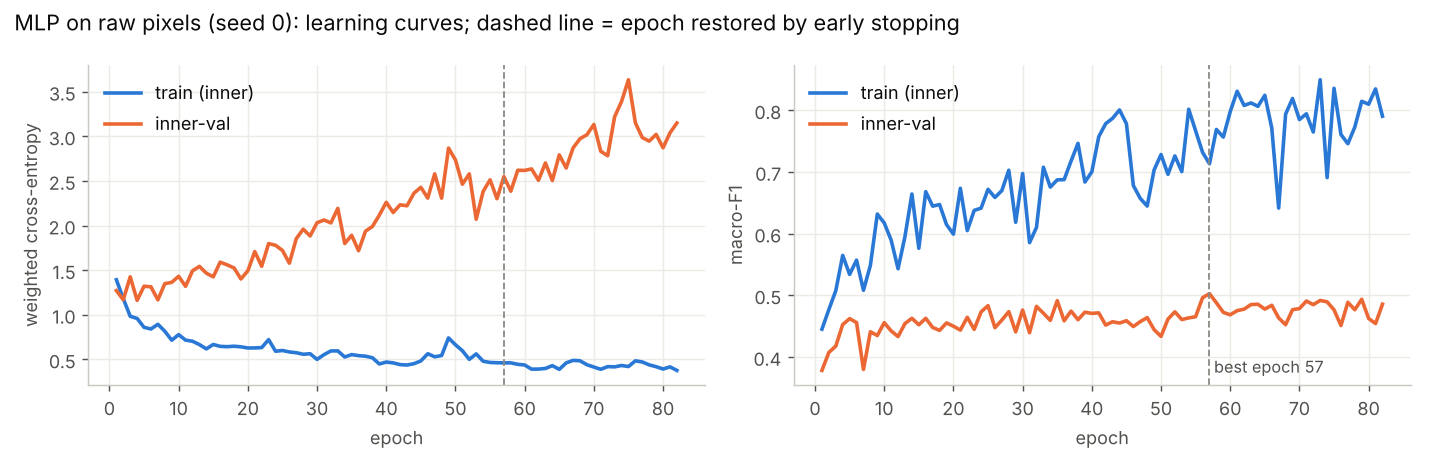

In [17]:
plot_curves(runs_p[0].history, runs_p[0].best_epoch,
            "MLP on raw pixels (seed 0): learning curves; dashed line = epoch restored by early stopping",
            FIG / "fig4_mlp_pixels_curves.png")

**What did the first layer learn?** Each of the hidden units of the
first layer has one weight per input pixel, so its 3,072 weights can be
reshaped back to a 32×32×3 image. These are the 16 units with the
largest weight norm (each rescaled to [0, 1] for display).

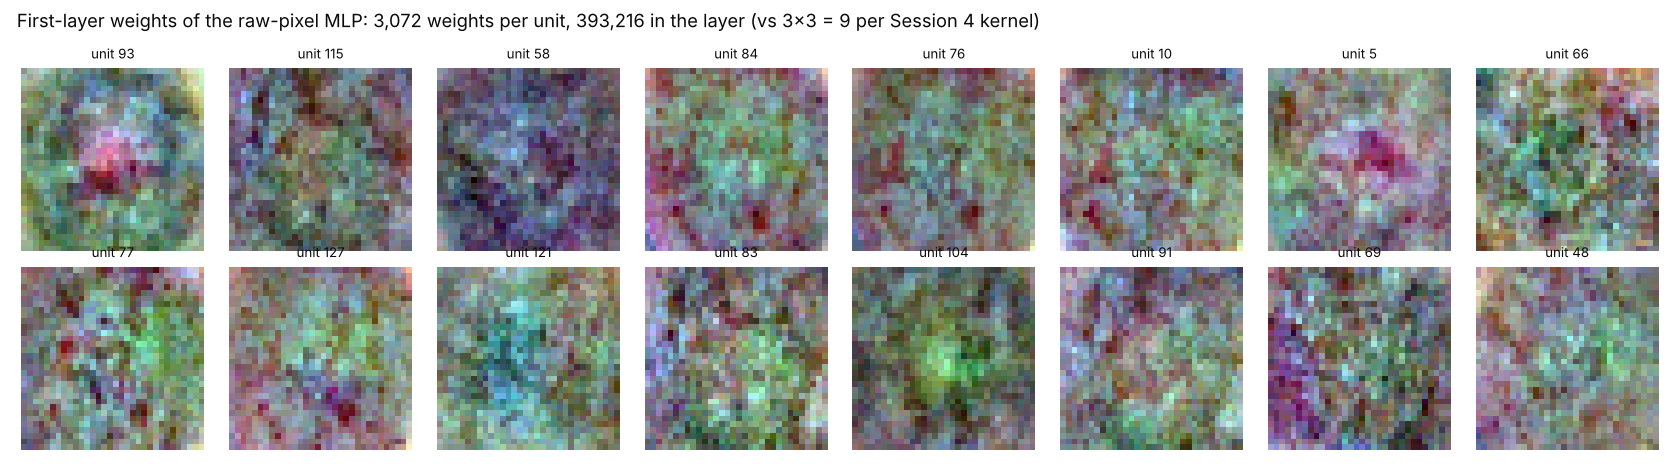

In [18]:
W = runs_p[0].model.net[0].weight.detach().numpy()          # (hidden, 3072)
top = np.argsort(-np.linalg.norm(W, axis=1))[:16]
fig, ax = plt.subplots(2, 8, figsize=(14, 3.9))
for a, u in zip(ax.ravel(), top):
    w = W[u].reshape(3, 32, 32).transpose(1, 2, 0)
    a.imshow((w - w.min()) / (w.max() - w.min() + 1e-12), interpolation="nearest")
    a.set_title(f"unit {u}", fontsize=8)
    a.axis("off")
fig.suptitle(f"First-layer weights of the raw-pixel MLP: {W.shape[1]:,} weights per unit, "
             f"{W.size:,} in the layer (vs 3×3 = 9 per Session 4 kernel)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig5_first_layer_weights.png", dpi=120)
plt.close()
display(IPyImage(filename=str(FIG / "fig5_first_layer_weights.png"), width=950))

**Robustness to label-preserving changes.** A skin lesion keeps its
diagnosis when the photo is mirrored or moved by a few pixels (this is
why flips are in the Milestone 1 augmentation). The trained raw-pixel
MLPs (5 seeds) are evaluated on the test images flipped left-right and
shifted 2 pixels to the right (`np.roll`); no retraining.

In [19]:
def transform_pixels(X, kind):
    img = X.reshape(len(X), 3, 32, 32)
    if kind == "flip":
        img = img[..., ::-1]
    elif kind == "shift2":
        img = np.roll(img, 2, axis=-1)
    return np.ascontiguousarray(img.reshape(len(X), -1))


rob = []
for kind in ["original", "flip", "shift2"]:
    Xt = Xp_test if kind == "original" else transform_pixels(Xp_test, kind)
    f1s, changed = [], []
    for r in runs_p:
        p0 = mlp.predict_proba(r.model, Xp_test).argmax(1)
        p1 = mlp.predict_proba(r.model, Xt).argmax(1)
        f1s.append(bl.metrics(y_test_lab, np.array(CLASSES)[p1])["macro_f1"])
        changed.append((p0 != p1).mean())
    rob.append({"test images": {"original": "original", "flip": "mirrored left-right",
                                "shift2": "shifted 2 px"}[kind],
                "test macro-F1 (mean of 5 seeds)": np.mean(f1s),
                "% of lesions whose prediction changes": 100 * np.mean(changed)})
rob = pd.DataFrame(rob)
rob.to_csv(RES / "pixels_robustness.csv", index=False)
display(rob)

,test images,test macro-F1 (mean of 5 seeds),% of lesions whose prediction changes
0,original,0.533,0.000
1,mirrored left-right,0.526,14.122
2,shifted 2 px,0.538,10.051


In [20]:
# --- Scoreboard (final) ----------------------------------------------------
SESSION = 6
for label, s, pv, pt, inputs, n_in in [
        ("MLP on raw pixels (mean of 5 seeds)", seeds_p, pval_p, ptest_p, "raw pixels 32×32×3, dermoscopic", 3072),
        ("MLP on raw pixels (mean of 5 seeds)", seeds_b2, pval_b2, ptest_b2, "raw pixels 32×32×3, both views", 6144)]:
    add_row(label, inputs, n_in, "train", s.val_macro_f1.mean(),
            {"macro_f1": s.test_macro_f1.mean(), "balanced_acc": s.test_balanced_acc.mean(),
             "macro_auc": s.test_macro_auc.mean(), "recall_Malignant": s.test_recall_Malignant.mean()},
            val_sd=s.val_macro_f1.std(), test_sd=s.test_macro_f1.std(),
            n_params=mlp.n_params(mlp.MLP(n_in, cfg_p["hidden"], cfg_p["p_drop"])))
    add_row("MLP on raw pixels (5-seed ensemble)", inputs, n_in, "train",
            bl.metrics(y_val_lab, np.array(CLASSES)[pv.argmax(1)], pv)["macro_f1"],
            bl.metrics(y_test_lab, np.array(CLASSES)[pt.argmax(1)], pt))

sb = pd.DataFrame(scoreboard)
sb.to_csv(ROOT / "reports" / "scoreboard.csv", index=False)
print("SCOREBOARD — all sessions (saved to reports/scoreboard.csv)")
display(pretty(sb))

pb_p = paired_bootstrap(ptest_p, ptest_b, y_test_lab)
pb_pf = paired_bootstrap(ptest_p, ptest_f, y_test_lab)
pd.DataFrame({"raw pixels − baseline": pb_p, "raw pixels − MLP on features": pb_pf,
              "MLP on features − baseline": pb_f}).T.to_csv(RES / "paired_bootstrap.csv")
print("Paired bootstrap on test (5-seed ensembles; baseline fit on train), 2,000 resamples:")
display(pd.DataFrame({"raw pixels − baseline": pb_p, "raw pixels − MLP on features": pb_pf,
                      "MLP on features − baseline": pb_f}).T)

SCOREBOARD — all sessions (saved to reports/scoreboard.csv)


,session,model,input,fit on,val macro-F1,test macro-F1,test AUC,test recall Malignant
0,3,dummy: always-Malignant,—,train,0.272,0.270,0.500,1.000
1,3,dummy: stratified-random,—,train,0.325,0.326,0.500,0.703
2,5,Baseline: HistGB + SVM-RBF ensemble,hand-crafted features + meta,train,0.563,0.664,0.873,0.916
3,5,Baseline: HistGB + SVM-RBF ensemble (official),hand-crafted features + meta,train + val,—,0.697,0.879,0.907
4,6,"MLP (256, 128), dropout 0.2 (mean of 5 seeds)",hand-crafted features + meta,train,0.556 ± 0.030,0.605 ± 0.012,0.838,0.861
5,6,MLP (5-seed ensemble),hand-crafted features + meta,train,0.576,0.632,0.858,0.896
6,6,MLP on raw pixels (mean of 5 seeds),"raw pixels 32×32×3, dermoscopic",train,0.517 ± 0.020,0.533 ± 0.018,0.779,0.790
7,6,MLP on raw pixels (5-seed ensemble),"raw pixels 32×32×3, dermoscopic",train,0.542,0.571,0.812,0.819
8,6,MLP on raw pixels (mean of 5 seeds),"raw pixels 32×32×3, both views",train,0.535 ± 0.012,0.566 ± 0.019,0.811,0.799
9,6,MLP on raw pixels (5-seed ensemble),"raw pixels 32×32×3, both views",train,0.563,0.590,0.836,0.821


Paired bootstrap on test (5-seed ensembles; baseline fit on train), 2,000 resamples:


,diff,ci_low,ci_high,P(diff>0),auc_diff,auc_ci_low,auc_ci_high
raw pixels − baseline,-0.093,-0.208,0.037,0.077,-0.061,-0.116,-0.006
raw pixels − MLP on features,-0.061,-0.151,0.026,0.099,-0.047,-0.106,0.017
MLP on features − baseline,-0.032,-0.089,0.043,0.168,-0.014,-0.037,0.006


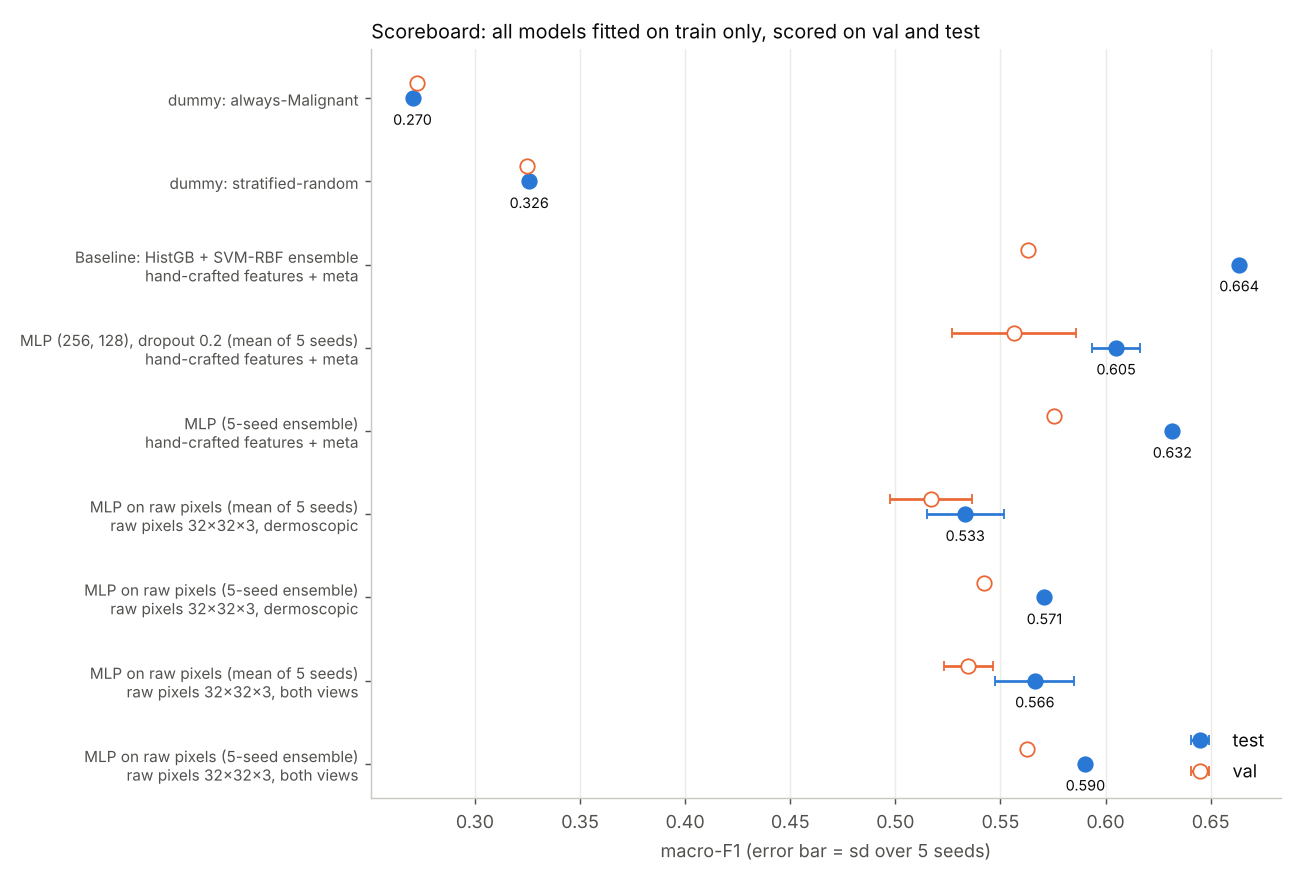

In [21]:
plot_rows = sb[sb.fit_on == "train"].copy()
plot_rows["label"] = [f"{m}\n{i}" if i != "—" else m for m, i in zip(plot_rows.model, plot_rows.input)]
plot_rows = plot_rows.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.62 * len(plot_rows) + 1.2))
yy = np.arange(len(plot_rows))
ax.errorbar(plot_rows.test_macro_f1, yy, xerr=plot_rows.test_sd.fillna(0), fmt="o", color=BLUE,
            ms=8, capsize=3, label="test", zorder=3)
ax.errorbar(plot_rows.val_macro_f1, yy + 0.18, xerr=plot_rows.val_sd.fillna(0), fmt="o", mfc="white",
            mec=ORANGE, ecolor=ORANGE, ms=8, capsize=3, label="val", zorder=3)
for y_, v in zip(yy, plot_rows.test_macro_f1):
    ax.text(v, y_ - 0.32, f"{v:.3f}", ha="center", fontsize=8, color=INK)
ax.set_yticks(yy, plot_rows.label, fontsize=8.5)
ax.set_xlabel("macro-F1 (error bar = sd over 5 seeds)")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Scoreboard: all models fitted on train only, scored on val and test", loc="left")
plt.tight_layout()
plt.savefig(FIG / "fig6_scoreboard.png", dpi=130)
plt.close()
display(IPyImage(filename=str(FIG / "fig6_scoreboard.png"), width=900))

## 4. Question 3 — Answer: raw pixels are **worse** than features

| MLP, same architecture family and training (all fitted on train) | inputs | val macro-F1 | test macro-F1 | test macro AUC |
|---|---|---|---|---|
| hand-crafted features + meta (§1) | 323 | 0.556 ± 0.030 | 0.605 ± 0.012 | 0.838 |
| **raw pixels, dermoscopic 32×32×3** | **3,072** | **0.517 ± 0.020** | **0.533 ± 0.018** | **0.779** |
| raw pixels, both views | 6,144 | 0.535 ± 0.012 | 0.566 ± 0.019 | 0.811 |
| raw pixels, dermoscopic, **pixels shuffled** | 3,072 | 0.521 ± 0.021 | 0.537 ± 0.018 | 0.785 |
| *Session 5 baseline (features)* | *323* | *0.563* | *0.664* | *0.873* |

**Worse, consistently.** The raw-pixel MLP is below the MLP on features
on val (0.517 vs 0.556), on test (0.533 vs 0.605) and in AUC (0.779 vs
0.838). On test, every one of its 5 seeds (0.509–0.558) is below every
seed of the feature MLP (0.591–0.618). Against the Session 5 baseline
the gap is larger: 0.533 vs 0.664 test macro-F1, 0.779 vs 0.873 AUC.
On the test set alone the macro-F1 gap of the ensembles is not
conclusive (−0.093, 95% CI [−0.208, +0.037]). With only 13
Indeterminate lesions, macro-F1 is very noisy. Macro AUC, which uses
the probabilities of all 786 lesions, is less noisy: there the raw-pixel
MLP is **significantly worse than the baseline** (−0.061, 95% CI
[−0.116, −0.006]) and worse than the feature MLP (−0.047, CI [−0.106,
+0.017]). The ranking is the same on val, test and AUC. Using both views (6,144 inputs) helps (0.566 on test),
but it still does not reach the features.

Raw pixels still beat the dummies by a wide margin (0.53 vs 0.33).
Colour alone carries a lot of signal: in Session 5 the colour family
alone reached 0.566 CV macro-F1. A 32×32 thumbnail keeps colour.

**Why worse — five reasons, each measured above:**

1. **Information is lost at 32×32.** The features were computed on
   224×224 images, 49 times more pixels. Dermoscopic structures
   (pigment network, dots, vessels, hairs) are a few pixels wide at 224
   and vanish at 32 (figure in §3). Texture, one of the two strongest
   Session 5 families, cannot be recovered from the thumbnail; mainly colour and a
   coarse blob survive.
2. **An MLP ignores where pixels are.** Shuffling the 3,072 inputs with
   one fixed permutation gives the *same* score: 0.537 vs 0.533 on
   test, 0.521 vs 0.517 on val. To a fully connected layer an image is
   an unordered list of numbers. Neighbourhoods, edges and textures,
   which Session 4's filters were built on, are not used at all.
3. **No invariance.** A mirrored lesion has the same diagnosis, yet
   mirroring the test images changes the prediction for 14% of
   lesions, and a 2-pixel shift changes 10%. The hand-crafted features
   (colour histograms, GLCM averaged over four angles, LBP histograms,
   shape) are largely insensitive to these changes by construction. The
   MLP would have to learn the same pattern separately at every
   position.
4. **Too many parameters for the data.** The first layer alone has
   3,072 × 128 = 393,216 weights for ~3,100 training lesions, about
   126 per lesion. The learning curves show classic overfitting:
   inner-val loss rises from the first epochs while train loss falls,
   and at the restored epoch train macro-F1 is ≈0.72 vs ≈0.50 on
   inner-val. Config selection itself picked the smallest network with
   the strongest dropout (128 units, 0.5). Its weight images are noisy
   whole-image templates, not local filters.
5. **The features contain domain knowledge.** They include lesion-vs-
   skin colour contrast in Lab, ABCD asymmetry and border irregularity,
   both views and metadata. The pixel MLP would have to discover all of
   that from 3,668 examples.

**What this motivates (Milestone 2).** All five problems are what a
convolutional network addresses, using exactly the `nn.Conv2d` of §2:
- small local kernels (`kernel_size=3`) look at neighbourhoods (fixes 2);
- the same kernel is reused at every position (weight sharing), so a
  layer with eight 3×3 RGB filters has 224 parameters instead of 393,216
  (fixes 4), and a pattern learned in one place is detected everywhere
  (fixes 3);
- `stride` / pooling build up from edges to textures to lesion
  structure at a resolution where texture still exists (fixes 1);
- the Milestone 1 augmentations (flips, small rotations) teach the
  remaining invariances.

The scoreboard (`reports/scoreboard.csv`) now holds the dummies, the
Session 5 baseline and the Session 6 MLPs on the same splits and
metrics. The CNN of Milestone 2 has to beat the 0.664 / 0.873 (macro-F1
/ AUC, fit on train) of the feature baseline, not just the raw-pixel
MLP.